# Query encoding versus query value

We contrast two ways in which a query can act on a two-qubit data-reuploading circuit. In the top row, panels (a)–(c), the query *encoding* is varied through the interpolation angle $\alpha$ at a fixed query $\boldsymbol f$ (`fig_01_vary_encoding.ipynb`). In the bottom row, panels (d)–(f), the query *value* is varied along the ray $\boldsymbol f(t) = t\,(1, 1)$ with the encoding fixed (`fig_02_vary_query.ipynb`).

The columns are the three tests: the naive shape change $\Delta$ at one fixed parameter vector, the class witness $S$ (the maximum nonseparable weight of the $\boldsymbol x$-coefficient matrix, nonzero only if the hypothesis class changes), and the jackknife-corrected spectral-prior distance $D_\Sigma$ with 95% bands, where the grey region marks the Haar null. The three series realise the trichotomy: (I) absorbable query with Haar prior, inert; (II) absorbable query with a narrow Gaussian prior, reweighting only; (III) nonlocal query with Haar prior, class change. Nothing is computed here; the notebook loads and plots the curves written by the two producer notebooks.

**Outputs.** `figures/fig_01_02_combined.pdf` (and `.png`) — the six-panel figure; `results/fig_01_02/` — curves written by the two producer notebooks, read here.

**Runtime.** With the cached results in `results/fig_01_02/` the notebook runs in under a minute. Recomputing from scratch takes a few minutes per producer notebook on a CPU: delete `query_encoding_interpolation_product_results.npz` and `query_inductive_bias_product_results.npz`, then run `fig_01_vary_encoding.ipynb` and `fig_02_vary_query.ipynb` before this notebook. Figure text is typeset with LaTeX when a working installation is found and with matplotlib mathtext otherwise; set `USE_TEX=0` to force mathtext.

## Setup

We import the plotting libraries and set the input and output directories.

In [1]:
import os
import shutil
import subprocess
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

RESULTS_DIR = Path("../results/fig_01_02")
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## Load results

For each series, both producers save the shape change, the class witness, the prior distance and its standard error, together with the abscissa, the Haar noise ceiling and the type of trainable block. `TRAINABLE_BLOCKS` selects the result files; the default `product` is the variant shown in the paper. As a quick check we print the grid size, the noise ceiling and the largest class witness of each sweep.

In [2]:
TRAINABLE_BLOCKS = os.environ.get("TRAINABLE_BLOCKS", "product").lower()

ENCODING_RESULTS = RESULTS_DIR / f"query_encoding_interpolation_{TRAINABLE_BLOCKS}_results.npz"
QUERY_RESULTS = RESULTS_DIR / f"query_inductive_bias_{TRAINABLE_BLOCKS}_results.npz"

SERIES = ("local", "local_narrow", "nonlocal")
QUANTITIES = (
    "shape_change",
    "nonseparable_weight",
    "prior_distance",
    "prior_distance_error",
)


def load_results(path, abscissa_key):
    """Read one saved results file into {quantity: {series: array}}."""
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. Run the corresponding notebook once to "
            "write it."
        )
    with np.load(path) as data:
        results = {
            quantity: {
                series: data[f"{quantity}__{series}"] for series in SERIES
            }
            for quantity in QUANTITIES
        }
        results["abscissa"] = data[abscissa_key]
        results["noise_ceiling"] = float(data["noise_ceiling"])
        results["trainable_blocks"] = str(data["trainable_blocks"])
        results["extra"] = {
            key: data[key]
            for key in ("fixed_query_vector", "query_direction")
            if key in data
        }
    return results


encoding = load_results(ENCODING_RESULTS, "encoding_angles")
query = load_results(QUERY_RESULTS, "query_values")

for name, results in (("encoding", encoding), ("query", query)):
    print(
        f"{name}: {results['abscissa'].size} points, "
        f"noise ceiling {results['noise_ceiling']:.4f}, "
        f"max S {max(np.max(v) for v in results['nonseparable_weight'].values()):.4f}"
    )

encoding: 181 points, noise ceiling 0.0033, max S 0.6644
query: 181 points, noise ceiling 0.0040, max S 0.6948


## Plotting helpers

We set the figure style: LaTeX text when a working installation is available (checked by running `kpsewhich`, not only by finding the binaries), serif fonts at 8 pt, and one colour and dash pattern per series.

In [3]:
def latex_is_usable():
    """Report whether matplotlib's usetex backend can actually run here."""
    if shutil.which("latex") is None or shutil.which("dvipng") is None:
        return False
    try:
        completed = subprocess.run(
            ["kpsewhich", "latex.ltx"],
            capture_output=True,
            timeout=30,
            check=False,
        )
    except (OSError, subprocess.SubprocessError):
        return False
    return completed.returncode == 0 and bool(completed.stdout.strip())


USE_TEX = os.environ.get("USE_TEX", "1") == "1" and latex_is_usable()

mpl.rcParams.update(
    {
        "text.usetex": USE_TEX,
        "text.latex.preamble": r"\usepackage{amsmath}\usepackage{bm}",
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "axes.linewidth": 0.6,
        "axes.spines.top": True,
        "axes.spines.right": True,
        "xtick.labelsize": 7.5,
        "ytick.labelsize": 7.5,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "xtick.minor.width": 0.4,
        "ytick.minor.width": 0.4,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "legend.fontsize": 6.9,
        "legend.handlelength": 2.1,
        "legend.columnspacing": 1.2,
        "lines.linewidth": 1.3,
        "savefig.bbox": None,
    }
)

COLOR = {
    "local": "#0072B2",
    "local_narrow": "#009E73",
    "nonlocal": "#D55E00",
}
STYLE = {
    "local": (0, (4, 2)),
    "local_narrow": (0, (5, 1.5, 1, 1.5)),
    "nonlocal": "-",
}
BAND_ALPHA = {"local": 0.12, "local_narrow": 0.13, "nonlocal": 0.14}
LEGEND_ORDER = ("local", "local_narrow", "nonlocal")
LABEL = {
    "local": r"(I) Absorbable, Haar",
    "local_narrow": r"(II) Absorbable, narrow Gaussian",
    "nonlocal": r"(III) Nonlocal, Haar",
}

`plot_series` draws the three series, optionally with 95% bands clipped at zero, and returns the upper end of the plotted data so that the axis limits can follow it. `query_vector_label` writes the fixed query of the top row, recognising simple fractions of $\pi$.

In [4]:
def plot_series(axis, abscissa, values, errors=None):
    """Draw every series, with an optional 95 percent band."""
    upper = -np.inf
    for series in SERIES:
        axis.plot(
            abscissa,
            values[series],
            color=COLOR[series],
            ls=STYLE[series],
        )
        if errors is None:
            upper = max(upper, np.max(values[series]))
            continue

        half_width = 1.96 * errors[series]
        axis.fill_between(
            abscissa,
            np.maximum(0.0, values[series] - half_width),
            values[series] + half_width,
            color=COLOR[series],
            alpha=BAND_ALPHA[series],
            linewidth=0,
        )
        upper = max(upper, np.max(values[series] + half_width))
    return upper


def query_vector_label(vector):
    """A LaTeX label for the fixed query hyperparameter."""
    named = {
        np.pi / 2.0: r"\pi/2",
        np.pi / 3.0: r"\pi/3",
        np.pi / 4.0: r"\pi/4",
        np.pi / 6.0: r"\pi/6",
    }
    components = []
    for value in vector:
        for reference, text in named.items():
            if np.isclose(value, reference):
                components.append(text)
                break
        else:
            components.append(f"{value:.3f}")
    return r"$f=(" + ",".join(components) + r")$"

`plot_row` fills the three panels of one sweep: shape change, class witness and prior distance. The prior-distance axis is linear inside the Haar null and logarithmic above it.

In [5]:
def plot_row(axes, results, variable, configure_axis, labels, descriptions=None):
    """Panels (shape change, class witness, prior distance) for one sweep."""
    abscissa = results["abscissa"]
    noise_ceiling = results["noise_ceiling"]
    x_mid = 0.5 * (abscissa[0] + abscissa[-1])

    # naive test: coefficient direction at one fixed parameter vector
    ax = axes[0]
    plot_series(ax, abscissa, results["shape_change"])
    configure_axis(ax)
    ax.set_ylim(0.0, 1.02)
    ax.set_ylabel(rf"Shape change $\Delta({variable})$")
    ax.set_title(labels[0], loc="left", pad=4, fontweight="bold")

    # class test: existence of a nonseparable function
    ax = axes[1]
    upper_weight = plot_series(ax, abscissa, results["nonseparable_weight"])
    configure_axis(ax)
    ax.set_ylim(-0.045 * upper_weight, 1.12 * upper_weight)
    ax.axhline(0.0, color="0.55", linewidth=0.5, zorder=0)
    ax.set_ylabel(rf"Class witness $S({variable})$")
    ax.set_title(labels[1], loc="left", pad=4, fontweight="bold")
    if results["trainable_blocks"] == "product":
        ax.annotate(
            rf"(I), (II): $S({variable})=0$ exactly",
            xy=(x_mid, 0.0),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=6.6,
            color="0.25",
        )

    # prior test: change in the parameter-induced spectral second moment
    ax = axes[2]
    upper_distance = plot_series(
        ax,
        abscissa,
        results["prior_distance"],
        results["prior_distance_error"],
    )
    configure_axis(ax)
    ax.axhspan(
        0.0,
        noise_ceiling,
        color="0.80",
        alpha=0.55,
        linewidth=0,
        zorder=0,
    )
    # linear inside the sampling null, logarithmic above it
    ax.set_yscale("symlog", linthresh=noise_ceiling, linscale=0.35)
    ax.set_ylim(0.0, max(1.0, 1.6 * upper_distance))
    ax.annotate(
        "Haar null",
        xy=(abscissa[0] + 0.05 * (abscissa[-1] - abscissa[0]), noise_ceiling),
        xytext=(0, -1),
        textcoords="offset points",
        ha="left",
        va="top",
        fontsize=6.6,
        color="0.25",
    )
    ax.set_ylabel(rf"Spectral-prior distance $D_{{\Sigma}}({variable})$")
    ax.set_title(labels[2], loc="left", pad=4, fontweight="bold")
    if descriptions is not None:
        for ax, description in zip(axes, descriptions):
            ax.set_title(
                description, loc="right", pad=4, fontsize=7.0, color="0.25"
            )
    return upper_weight

Axis settings for the two sweeps: the encoding angle $\alpha \in [0, \pi/2]$ and the ray parameter $t \in [0, 2\pi]$.

In [6]:
def configure_encoding_axis(axis):
    axis.set_xlim(0.0, np.pi / 2.0)
    axis.set_xticks([0.0, np.pi / 4.0, np.pi / 2.0])
    axis.set_xticklabels([r"$0$", r"$\pi/4$", r"$\pi/2$"])
    axis.set_xlabel(r"Encoding interpolation $\alpha$")


def configure_query_axis(axis):
    axis.set_xlim(0.0, 2.0 * np.pi)
    axis.set_xticks([0.0, np.pi, 2.0 * np.pi])
    axis.set_xticklabels([r"$0$", r"$\pi$", r"$2\pi$"])
    axis.set_xlabel(r"Query path parameter $t$")

## Figure

We draw the encoding sweep in the top row and the query sweep in the bottom row, with one shared legend and the column descriptions on the top row only. In panel (e) we mark the partial recurrence at $t = \pi$, where the second query layer returns to the identity (see `fig_02_vary_query.ipynb`). The figure is saved as PDF and PNG.

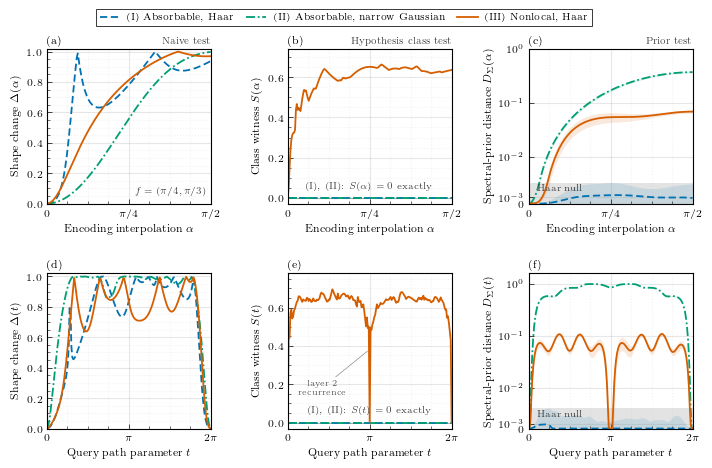

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(7.08, 4.75))

handles = [
    Line2D([], [], color=COLOR[series], ls=STYLE[series], label=LABEL[series])
    for series in LEGEND_ORDER
]
legend = fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.998),
    ncol=3,
    frameon=True,
    framealpha=0.9,
    edgecolor="black",
    fancybox=False,
)
legend.get_frame().set_linewidth(0.6)

# top row: encoding interpolation at a fixed query; the column descriptions
# apply to both rows
plot_row(
    axes[0],
    encoding,
    r"\alpha",
    configure_encoding_axis,
    ("(a)", "(b)", "(c)"),
    ("Naive test", "Hypothesis class test", "Prior test"),
)
if "fixed_query_vector" in encoding["extra"]:
    axes[0, 0].annotate(
        query_vector_label(encoding["extra"]["fixed_query_vector"]),
        xy=(0.97, 0.05),
        xycoords="axes fraction",
        ha="right",
        va="bottom",
        fontsize=7,
        color="0.25",
    )

# bottom row: query value along a ray
upper_weight = plot_row(axes[1], query, "t", configure_query_axis, ("(d)", "(e)", "(f)"))
# at t = pi the second query layer returns to the identity for direction
# components summing to something other than one; see fig_02_vary_query
direction = query["extra"].get("query_direction")
if direction is not None and abs(float(np.sum(direction)) - 1.0) > 1e-12:
    axes[1, 1].annotate(
        "layer 2\nrecurrence",
        xy=(np.pi, 0.55 * upper_weight),
        xytext=(0.42 * np.pi, 0.26 * upper_weight),
        ha="center",
        va="center",
        fontsize=6.2,
        color="0.35",
        arrowprops=dict(
            arrowstyle="-",
            color="0.55",
            linewidth=0.5,
            shrinkA=0.0,
            shrinkB=2.0,
        ),
    )

for ax in axes.flat:
    ax.set_axisbelow(True)
    ax.minorticks_on()
    ax.tick_params(which="both", top=False, right=False)
    ax.grid(True, which="major", linestyle="-", alpha=0.30)
    ax.grid(True, which="minor", linestyle=":", alpha=0.15)
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

fig.subplots_adjust(
    left=0.080,
    right=0.992,
    bottom=0.105,
    top=0.905,
    wspace=0.47,
    hspace=0.45,
)

suffix = "" if TRAINABLE_BLOCKS == "product" else f"_{TRAINABLE_BLOCKS}"
output_stem = FIGURES_DIR / f"fig_01_02_combined{suffix}"
fig.savefig(f"{output_stem}.pdf", pad_inches=0.05, bbox_inches="tight")
fig.savefig(f"{output_stem}.png", dpi=600, pad_inches=0.05, bbox_inches="tight")
plt.show()

## Summary

Varying the query encoding at a fixed query and varying the query value at a fixed encoding give the same pattern across the three tests. The naive shape change $\Delta$ is large for all three series and does not separate them. The class witness $S$ is exactly zero for the absorbable series (I) and (II) and nonzero only for the nonlocal series (III), while the spectral-prior distance $D_\Sigma$ stays inside the Haar null for (I) and leaves it for (II) and (III).